# DAY 2: Propagating orbits and calculating H
#### *Open Tools, Open Sky: Doing LSST Science with Public Rubin Data & LINCC Frameworks, UdeA, Medellín, October 13 2026*

# Propagating an orbit with `spiceypy.prop2b`

`state = spiceypy.prop2b(gm, pvinit, dt)` propagates a state vector under pure two-body (Keplerian) motion.

- `gm`: gravitational parameter of the central body (km³/s²)
- `pvinit`: initial state `[x, y, z, vx, vy, vz]` in km and km/s, relative to the central body
- `dt`: time to propagate, in seconds (can be negative to go backwards)
- returns: the state after `dt`, in the same frame and units

No kernels are needed: `prop2b` only uses the numbers you give it.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import spiceypy


## 1. Single propagation: a circular orbit at 1 AU around the Sun

In [2]:
gm_sun = 1.32712440018e11   # km^3/s^2
au = 1.495978707e8          # km

# Start on the +x axis, moving in +y at circular speed
v_circ = np.sqrt(gm_sun / au)
pvinit = np.array([au, 0.0, 0.0, 0.0, v_circ, 0.0])

# Propagate a quarter of a year
dt = 365.25 * 86400 / 4     # seconds
state = spiceypy.prop2b(gm_sun, pvinit, dt)

print("position (AU):", np.array(state[:3]) / au)   # should be ~[0, 1, 0]
print("velocity (km/s):", state[3:])                 # should be ~[-29.78, 0, 0]

position (AU): [2.96665647e-05 1.00000000e+00 0.00000000e+00]
velocity (km/s): [-2.97846918e+01  8.83609487e-04  0.00000000e+00]


In [3]:
def propagate_orbit(gm, state, dt):
    """Propagate a state vector under two-body motion with spiceypy.prop2b.

    Parameters
    ----------
    gm : float
        Gravitational parameter of the central body (km^3/s^2).
    state : array_like, shape (6,)
        Initial state [x, y, z, vx, vy, vz] in km and km/s.
    dt : float or array_like
        Time(s) to propagate, in seconds. Negative values propagate backwards.

    Returns
    -------
    numpy.ndarray
        Shape (6,) if dt is a scalar, or (len(dt), 6) if dt is an array.
    """
    state = np.ascontiguousarray(state, dtype=float)   # prop2b needs a contiguous array (not a strided view)
    if np.isscalar(dt):
        return np.array(spiceypy.prop2b(gm, state, dt))
    return np.array([spiceypy.prop2b(gm, state, t) for t in dt])

## 3. Propagating over many times to trace the orbit

Here an elliptical orbit: same start point but 20% faster than circular.

In [4]:
pvinit_ell = np.array([au, 0.0, 0.0, 0.0, 1.2 * v_circ, 0.0])

times = np.linspace(0, 3 * 365.25 * 86400, 1000)   # 3 years, in seconds
states = propagate_orbit(gm_sun, pvinit_ell, times)

x, y = states[:, 0] / au, states[:, 1] / au

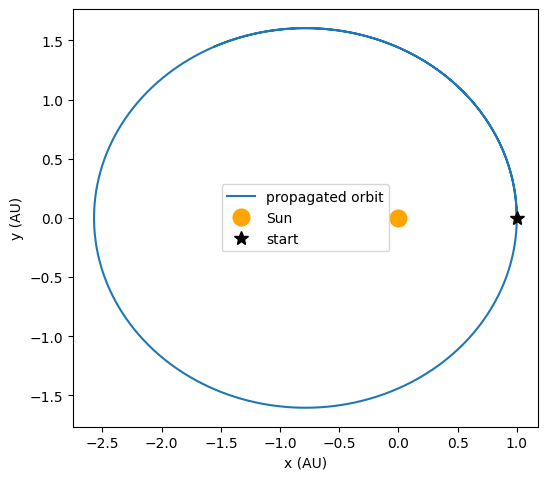

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x, y, label="propagated orbit")
ax.plot(0, 0, "o", color="orange", markersize=12, label="Sun")
ax.plot(x[0], y[0], "k*", markersize=10, label="start")
ax.set_xlabel("x (AU)")
ax.set_ylabel("y (AU)")
ax.set_aspect("equal")
ax.legend()
plt.show()

## 4. Sanity check: energy should be conserved

In [6]:
r = np.linalg.norm(states[:, :3], axis=1)
v = np.linalg.norm(states[:, 3:], axis=1)
energy = 0.5 * v**2 - gm_sun / r
print("relative energy variation:", np.ptp(energy) / abs(energy[0]))

relative energy variation: 2.700336860444668e-14


## Let's get the orbit in each observation time for each object

In [7]:
import pandas as pd

data_mpc = pd.read_parquet('data/obs_elements_state.parquet', engine='pyarrow')

In [ ]:
data_mpc[data_mpc['provid'] == '2025 MD38']

,obstime,permid,provid,mag,rmsmag,mpc_row,match_by,mpc_designation,mpc_a,mpc_e,...,mpc_epoch_mjd,mpc_H,mpc_tp_jd,x,y,z,vx,vy,vz,epoch_et
17134,2025-04-22 02:37:21.011,None,2025 MD38,21.955,0.058,1020544,other_desig,2014 HR48,3.15623,0.021533,...,61200.0,17.92,2460909.62099,-3.112026e+07,-4.527700e+08,-1.054155e+08,16.709462,-0.753608,-2.972021,834235200.0
17135,2025-04-22 02:38:48.940,None,2025 MD38,21.941,0.045,1020544,other_desig,2014 HR48,3.15623,0.021533,...,61200.0,17.92,2460909.62099,-3.112026e+07,-4.527700e+08,-1.054155e+08,16.709462,-0.753608,-2.972021,834235200.0
17136,2025-04-22 02:39:32.840,None,2025 MD38,21.928,0.047,1020544,other_desig,2014 HR48,3.15623,0.021533,...,61200.0,17.92,2460909.62099,-3.112026e+07,-4.527700e+08,-1.054155e+08,16.709462,-0.753608,-2.972021,834235200.0
17137,2025-04-22 02:42:38.583,None,2025 MD38,21.974,0.045,1020544,other_desig,2014 HR48,3.15623,0.021533,...,61200.0,17.92,2460909.62099,-3.112026e+07,-4.527700e+08,-1.054155e+08,16.709462,-0.753608,-2.972021,834235200.0
17138,2025-04-22 02:43:22.655,None,2025 MD38,21.917,0.045,1020544,other_desig,2014 HR48,3.15623,0.021533,...,61200.0,17.92,2460909.62099,-3.112026e+07,-4.527700e+08,-1.054155e+08,16.709462,-0.753608,-2.972021,834235200.0
17139,2025-04-22 02:44:50.066,None,2025 MD38,21.936,0.049,1020544,other_desig,2014 HR48,3.15623,0.021533,...,61200.0,17.92,2460909.62099,-3.112026e+07,-4.527700e+08,-1.054155e+08,16.709462,-0.753608,-2.972021,834235200.0
17140,2025-04-22 02:46:18.177,None,2025 MD38,21.942,0.043,1020544,other_desig,2014 HR48,3.15623,0.021533,...,61200.0,17.92,2460909.62099,-3.112026e+07,-4.527700e+08,-1.054155e+08,16.709462,-0.753608,-2.972021,834235200.0
17141,2025-04-22 02:47:02.172,None,2025 MD38,21.913,0.049,1020544,other_desig,2014 HR48,3.15623,0.021533,...,61200.0,17.92,2460909.62099,-3.112026e+07,-4.527700e+08,-1.054155e+08,16.709462,-0.753608,-2.972021,834235200.0
17142,2025-04-22 02:47:46.365,None,2025 MD38,21.914,0.050,1020544,other_desig,2014 HR48,3.15623,0.021533,...,61200.0,17.92,2460909.62099,-3.112026e+07,-4.527700e+08,-1.054155e+08,16.709462,-0.753608,-2.972021,834235200.0
17143,2025-04-22 02:49:14.347,None,2025 MD38,21.877,0.046,1020544,other_desig,2014 HR48,3.15623,0.021533,...,61200.0,17.92,2460909.62099,-3.112026e+07,-4.527700e+08,-1.054155e+08,16.709462,-0.753608,-2.972021,834235200.0


: 

In [8]:
data_mpc.head(30)

,obstime,permid,provid,mag,rmsmag,mpc_row,match_by,mpc_designation,mpc_a,mpc_e,...,mpc_epoch_mjd,mpc_H,mpc_tp_jd,x,y,z,vx,vy,vz,epoch_et
0,2025-05-02 00:42:01.796,None,2025 MD8,23.096,0.124,1487851,provid,2025 MD8,2.814204,0.119711,...,61200.0,18.65,2462050.80033,-2.605095e+07,-4.703152e+08,1.745239e+07,15.686788,-0.834262,-1.049584,834235200.0
1,2025-05-02 00:39:54.996,None,2025 MD8,22.927,0.127,1487851,provid,2025 MD8,2.814204,0.119711,...,61200.0,18.65,2462050.80033,-2.605095e+07,-4.703152e+08,1.745239e+07,15.686788,-0.834262,-1.049584,834235200.0
2,2025-05-02 01:01:01.387,None,2025 MD8,23.055,0.105,1487851,provid,2025 MD8,2.814204,0.119711,...,61200.0,18.65,2462050.80033,-2.605095e+07,-4.703152e+08,1.745239e+07,15.686788,-0.834262,-1.049584,834235200.0
3,2025-05-02 01:03:10.218,None,2025 MD8,23.059,0.129,1487851,provid,2025 MD8,2.814204,0.119711,...,61200.0,18.65,2462050.80033,-2.605095e+07,-4.703152e+08,1.745239e+07,15.686788,-0.834262,-1.049584,834235200.0
4,2025-05-02 01:29:18.645,None,2025 MD8,22.911,0.072,1487851,provid,2025 MD8,2.814204,0.119711,...,61200.0,18.65,2462050.80033,-2.605095e+07,-4.703152e+08,1.745239e+07,15.686788,-0.834262,-1.049584,834235200.0
5,2025-05-02 02:46:01.182,None,2025 MD8,23.957,0.171,1487851,provid,2025 MD8,2.814204,0.119711,...,61200.0,18.65,2462050.80033,-2.605095e+07,-4.703152e+08,1.745239e+07,15.686788,-0.834262,-1.049584,834235200.0
6,2025-05-02 02:41:08.571,None,2025 MP24,24.027,0.152,1488216,provid,2025 MP24,2.355546,0.081328,...,61200.0,19.88,2460950.66658,2.820841e+08,-1.964996e+08,-3.253941e+06,12.562880,15.356506,-1.336509,834235200.0
7,2025-05-02 01:50:19.014,None,2025 MP24,22.737,0.065,1488216,provid,2025 MP24,2.355546,0.081328,...,61200.0,19.88,2460950.66658,2.820841e+08,-1.964996e+08,-3.253941e+06,12.562880,15.356506,-1.336509,834235200.0
8,2025-05-02 01:52:26.255,None,2025 MP24,22.742,0.076,1488216,provid,2025 MP24,2.355546,0.081328,...,61200.0,19.88,2460950.66658,2.820841e+08,-1.964996e+08,-3.253941e+06,12.562880,15.356506,-1.336509,834235200.0
9,2025-05-02 02:18:03.173,None,2025 MP24,23.609,0.116,1488216,provid,2025 MP24,2.355546,0.081328,...,61200.0,19.88,2460950.66658,2.820841e+08,-1.964996e+08,-3.253941e+06,12.562880,15.356506,-1.336509,834235200.0


In [9]:
obj_test_1 = data_mpc[data_mpc['mpc_designation'] == '2021 LD56']
obj_test_1

,obstime,permid,provid,mag,rmsmag,mpc_row,match_by,mpc_designation,mpc_a,mpc_e,...,mpc_epoch_mjd,mpc_H,mpc_tp_jd,x,y,z,vx,vy,vz,epoch_et
228559,2025-06-22 05:26:04.208,None,2021 LD56,22.376,0.0950,1353570,provid,2021 LD56,40.233568,0.035963,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
228560,2025-07-02 03:51:36.254,None,2021 LD56,22.438,0.0434,1353570,provid,2021 LD56,40.233568,0.035963,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
228561,2025-08-15 04:36:59.089,None,2021 LD56,22.320,0.0648,1353570,provid,2021 LD56,40.233568,0.035963,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
7951040,2025-08-17 06:40:44.029,None,2021 LD56,22.192,0.1421,1353570,provid,2021 LD56,40.233568,0.035963,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
7951041,2025-08-17 07:06:23.698,None,2021 LD56,22.579,0.1441,1353570,provid,2021 LD56,40.233568,0.035963,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
7951042,2025-08-17 07:07:40.808,None,2021 LD56,22.919,0.1932,1353570,provid,2021 LD56,40.233568,0.035963,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
7951043,2025-07-08 08:40:03.023,None,2021 LD56,22.123,0.1113,1353570,provid,2021 LD56,40.233568,0.035963,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
7951044,2025-07-08 09:28:02.863,None,2021 LD56,22.081,0.1062,1353570,provid,2021 LD56,40.233568,0.035963,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
7951045,2025-07-08 09:29:20.847,None,2021 LD56,22.202,0.1242,1353570,provid,2021 LD56,40.233568,0.035963,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0
7951046,2025-07-08 02:06:14.033,None,2021 LD56,22.026,0.1288,1353570,provid,2021 LD56,40.233568,0.035963,...,61200.0,6.61,2463090.10383,2.751764e+09,-5.104135e+09,2.555672e+08,4.109701,2.30292,1.219266,834235200.0


### Propagate each observation from the MPC epoch to its observation time

The `x..vz` columns are the state at the MPC epoch (`epoch_et`). For each row we propagate by `dt = obs_et - epoch_et`.

In [10]:
# Leap seconds kernel (to convert UTC dates to ephemeris time) and the Sun's GM from DE440,
# the same GM used to build the state vectors at the MPC epoch
spiceypy.furnsh('kernels/naif0012.tls')
spiceypy.furnsh('kernels/gm_de440.tpc')
mu_sun = spiceypy.bodvrd('SUN', 'GM', 1)[1][0]   # km^3/s^2
AU_KM = 149597870.7                              # km

# Observation times as ephemeris time (seconds past J2000 TDB); Rubin obstime is UTC
obj_test_1 = obj_test_1.copy()
obj_test_1['obs_et'] = [spiceypy.str2et(t.strftime('%Y-%m-%d %H:%M:%S.%f UTC')) for t in obj_test_1['obstime']]

# Time from the MPC epoch of the elements to each observation
obj_test_1['dt'] = obj_test_1['obs_et'] - obj_test_1['epoch_et']

# Propagate the state at the MPC epoch to each observation time
state_cols = ['x', 'y', 'z', 'vx', 'vy', 'vz']
obs_states = np.array([propagate_orbit(mu_sun, row[state_cols].to_numpy(dtype=float), row['dt'])
                       for _, row in obj_test_1.iterrows()])
for k, col in enumerate(state_cols):
    obj_test_1[col + '_obs'] = obs_states[:, k]

obj_test_1[['obstime', 'dt'] + [c + '_obs' for c in state_cols]]

,obstime,dt,x_obs,y_obs,z_obs,vx_obs,vy_obs,vz_obs
228559,2025-06-22 05:26:04.208,-3.039317e+07,2.626008e+09,-5.172521e+09,2.184337e+08,4.165157,2.196945,1.224154
228560,2025-07-02 03:51:36.254,-2.953483e+07,2.629582e+09,-5.170634e+09,2.194843e+08,4.163627,2.199957,1.224027
228561,2025-08-15 04:36:59.089,-2.573051e+07,2.645409e+09,-5.162239e+09,2.241398e+08,4.156820,2.213291,1.223454
7951040,2025-08-17 06:40:44.029,-2.555029e+07,2.646158e+09,-5.161840e+09,2.243603e+08,4.156496,2.213923,1.223427
7951041,2025-08-17 07:06:23.698,-2.554875e+07,2.646165e+09,-5.161837e+09,2.243622e+08,4.156493,2.213928,1.223427
7951042,2025-08-17 07:07:40.808,-2.554867e+07,2.646165e+09,-5.161836e+09,2.243623e+08,4.156493,2.213928,1.223427
7951043,2025-07-08 08:40:03.023,-2.899913e+07,2.631812e+09,-5.169455e+09,2.201400e+08,4.162671,2.201836,1.223947
7951044,2025-07-08 09:28:02.863,-2.899625e+07,2.631824e+09,-5.169448e+09,2.201436e+08,4.162666,2.201846,1.223947
7951045,2025-07-08 09:29:20.847,-2.899617e+07,2.631825e+09,-5.169448e+09,2.201437e+08,4.162666,2.201846,1.223947
7951046,2025-07-08 02:06:14.033,-2.902276e+07,2.631714e+09,-5.169507e+09,2.201111e+08,4.162713,2.201753,1.223950


### Orbital elements at the observation time

`spiceypy.oscelt` converts each propagated state back to elements. In pure two-body motion only the mean anomaly $M$ changes; the other elements should match the MPC ones.

In [11]:
# oscelt returns [q, e, inc, node, peri, M, epoch, mu]: q in km, angles in radians
elts = np.array([spiceypy.oscelt(s, et, mu_sun)
                 for s, et in zip(obs_states, obj_test_1['obs_et'])])

obj_test_1['q_obs'] = elts[:, 0] / AU_KM
obj_test_1['e_obs'] = elts[:, 1]
obj_test_1['incl_obs'] = np.degrees(elts[:, 2])
obj_test_1['node_obs'] = np.degrees(elts[:, 3])
obj_test_1['peri_obs'] = np.degrees(elts[:, 4])
obj_test_1['M_obs'] = np.degrees(elts[:, 5])

obj_test_1[['obstime', 'mpc_q', 'q_obs', 'mpc_e', 'e_obs', 'mpc_incl', 'incl_obs',
            'mpc_node', 'node_obs', 'mpc_peri', 'peri_obs', 'mpc_M', 'M_obs']]

,obstime,mpc_q,q_obs,mpc_e,e_obs,mpc_incl,incl_obs,mpc_node,node_obs,mpc_peri,peri_obs,mpc_M,M_obs
228559,2025-06-22 05:26:04.208,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.343776
228560,2025-07-02 03:51:36.254,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.382143
228561,2025-08-15 04:36:59.089,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.552196
7951040,2025-08-17 06:40:44.029,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.560252
7951041,2025-08-17 07:06:23.698,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.560321
7951042,2025-08-17 07:07:40.808,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.560324
7951043,2025-07-08 08:40:03.023,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.406089
7951044,2025-07-08 09:28:02.863,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.406218
7951045,2025-07-08 09:29:20.847,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.406221
7951046,2025-07-08 02:06:14.033,38.786632,38.786632,0.035963,0.035963,14.7503,14.7503,288.69354,288.69354,17.80409,17.80409,352.70235,351.405033


## Compare with JPL Horizons: (162) Laurentia

We query JPL Horizons (`astroquery.jplhorizons`) for the osculating elements and state vector of a well-known main-belt asteroid, (162) Laurentia, at each Rubin observation time, and compare them with `propagate_orbit`.

- Horizons uses a full n-body integration (planets, large asteroids), while `prop2b` is pure two-body around the Sun, so the differences grow with the time from the MPC epoch.
- We ask Horizons for heliocentric (`500@10`) ecliptic J2000 values, the same frame as the MPC elements.
- We also query the MPC epoch itself: the difference there is between the MPC and JPL orbit solutions, before any propagation.

In [12]:
from astroquery.jplhorizons import Horizons

obj_test_2 = data_mpc[data_mpc['mpc_designation'] == '(162) Laurentia'].sort_values('obstime').copy()

# Observation times as ET; ET is TDB seconds past J2000 (JD 2451545.0 TDB), so JD_TDB follows directly
obj_test_2['obs_et'] = [spiceypy.str2et(t.strftime('%Y-%m-%d %H:%M:%S.%f UTC')) for t in obj_test_2['obstime']]
epoch_et = obj_test_2['epoch_et'].iloc[0]          # MPC epoch of the elements (same for every row)
jd_obs = 2451545.0 + obj_test_2['obs_et'].to_numpy() / 86400
jd_epoch = 2451545.0 + epoch_et / 86400

# Horizons epochs are JD TDB; first epoch = MPC epoch, then the observation times
horizons = Horizons(id='162', id_type='smallbody', location='500@10',
                    epochs=[jd_epoch] + jd_obs.tolist())
hor_el = horizons.elements(refplane='ecliptic').to_pandas()
hor_vec = horizons.vectors(refplane='ecliptic').to_pandas()

# Horizons returns the epochs sorted in time, so we work with the times it returns.
# Propagate the MPC state to exactly those epochs
hor_et = (hor_el['datetime_jd'].to_numpy() - 2451545.0) * 86400
state0 = obj_test_2[state_cols].iloc[0].to_numpy(dtype=float)
prop_states = propagate_orbit(mu_sun, state0, hor_et - epoch_et)
prop_el = np.array([spiceypy.oscelt(s, et, mu_sun) for s, et in zip(prop_states, hor_et)])

In [13]:
def wrap180(angle):
    """Angle difference wrapped to [-180, 180) degrees."""
    return (angle + 180) % 360 - 180

AU_PER_DAY = AU_KM / 86400                    # km/s in one AU/day
r_hor = hor_vec[['x', 'y', 'z']].to_numpy() * AU_KM
v_hor = hor_vec[['vx', 'vy', 'vz']].to_numpy() * AU_PER_DAY

comparison = pd.DataFrame({
    'date (UTC)': np.where(np.isclose(hor_et, epoch_et, atol=1.0), 'MPC epoch',
                          [spiceypy.et2utc(et, 'ISOC', 0) for et in hor_et]),
    'days_from_epoch': (hor_et - epoch_et) / 86400,
    'dq [km]': (prop_el[:, 0] / AU_KM - hor_el['q']) * AU_KM,
    'de': prop_el[:, 1] - hor_el['e'],
    'dincl [arcsec]': wrap180(np.degrees(prop_el[:, 2]) - hor_el['incl']) * 3600,
    'dnode [arcsec]': wrap180(np.degrees(prop_el[:, 3]) - hor_el['Omega']) * 3600,
    'dperi [arcsec]': wrap180(np.degrees(prop_el[:, 4]) - hor_el['w']) * 3600,
    'dM [arcsec]': wrap180(np.degrees(prop_el[:, 5]) - hor_el['M']) * 3600,
    'dr [km]': np.linalg.norm(prop_states[:, :3] - r_hor, axis=1),
    'dv [m/s]': np.linalg.norm(prop_states[:, 3:] - v_hor, axis=1) * 1000,
})
comparison

,date (UTC),days_from_epoch,dq [km],de,dincl [arcsec],dnode [arcsec],dperi [arcsec],dM [arcsec],dr [km],dv [m/s]
0,2025-09-03T08:46:25,-278.633632,-226931.748659,2.638286e-04,3.621527,-18.267462,248.932484,-259.037971,34207.153244,2.754458
1,2025-09-03T08:47:05,-278.633172,-226931.251116,2.638280e-04,3.621521,-18.267406,248.932156,-259.037563,34207.044696,2.754453
2,2025-09-03T08:49:04,-278.631787,-226929.751951,2.638261e-04,3.621504,-18.267237,248.931171,-259.036333,34206.714565,2.754439
3,2025-09-03T08:49:44,-278.631328,-226929.254612,2.638254e-04,3.621498,-18.267180,248.930844,-259.035925,34206.605801,2.754434
4,2025-09-03T08:51:44,-278.629943,-226927.755511,2.638235e-04,3.621481,-18.267011,248.929858,-259.034695,34206.275685,2.754420
5,2025-09-03T08:55:03,-278.627639,-226925.261634,2.638204e-04,3.621452,-18.266729,248.928219,-259.032650,34205.727451,2.754396
6,2025-09-03T08:57:42,-278.625792,-226923.262554,2.638178e-04,3.621429,-18.266503,248.926904,-259.031010,34205.288556,2.754377
7,2025-11-17T02:10:13,-203.908773,-156439.868741,1.770733e-04,2.644906,-10.195417,188.667173,-186.547249,18807.502880,2.033517
8,2025-11-17T03:46:59,-203.841569,-156381.429655,1.770032e-04,2.644025,-10.189388,188.609867,-186.481413,18795.701625,2.032886
9,2025-11-17T03:50:33,-203.839091,-156379.274776,1.770006e-04,2.643993,-10.189166,188.607754,-186.478985,18795.266574,2.032863


In [14]:
# Side by side: propagated (prop) vs Horizons (hor) elements at the observation times
side_by_side = pd.DataFrame({
    'date (UTC)': comparison['date (UTC)'],
    'q prop [AU]': prop_el[:, 0] / AU_KM, 'q hor [AU]': hor_el['q'],
    'e prop': prop_el[:, 1], 'e hor': hor_el['e'],
    'incl prop': np.degrees(prop_el[:, 2]), 'incl hor': hor_el['incl'],
    'node prop': np.degrees(prop_el[:, 3]), 'node hor': hor_el['Omega'],
    'peri prop': np.degrees(prop_el[:, 4]), 'peri hor': hor_el['w'],
    'M prop': np.degrees(prop_el[:, 5]), 'M hor': hor_el['M'],
})
side_by_side

,date (UTC),q prop [AU],q hor [AU],e prop,e hor,incl prop,incl hor,node prop,node hor,peri prop,peri hor,M prop,M hor
0,2025-09-03T08:46:25,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623502,205.515336,205.587291
1,2025-09-03T08:47:05,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623502,205.515423,205.587378
2,2025-09-03T08:49:04,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623502,205.515684,205.587638
3,2025-09-03T08:49:44,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623503,205.515770,205.587725
4,2025-09-03T08:51:44,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623503,205.516031,205.587985
5,2025-09-03T08:55:03,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623503,205.516465,205.588419
6,2025-09-03T08:57:42,2.461634,2.463151,0.183172,0.182908,6.09272,6.091714,35.4191,35.424174,115.69265,115.623504,205.516813,205.588766
7,2025-11-17T02:10:13,2.461634,2.462680,0.183172,0.182995,6.09272,6.091985,35.4191,35.421932,115.69265,115.640242,219.592989,219.644808
8,2025-11-17T03:46:59,2.461634,2.462679,0.183172,0.182995,6.09272,6.091986,35.4191,35.421930,115.69265,115.640258,219.605650,219.657451
9,2025-11-17T03:50:33,2.461634,2.462679,0.183172,0.182995,6.09272,6.091986,35.4191,35.421930,115.69265,115.640259,219.606117,219.657917


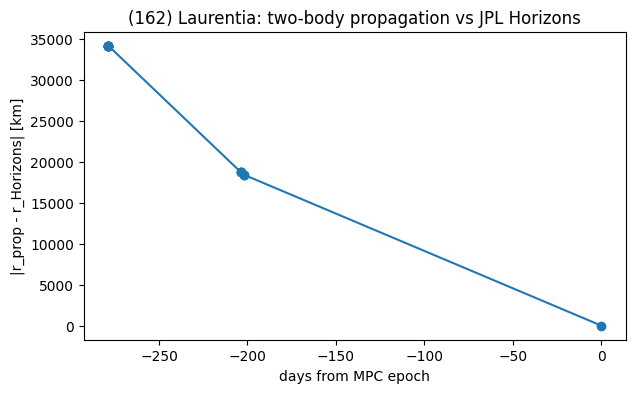

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(comparison['days_from_epoch'], comparison['dr [km]'], 'o-')
ax.set_xlabel('days from MPC epoch')
ax.set_ylabel('|r_prop - r_Horizons| [km]')
ax.set_title('(162) Laurentia: two-body propagation vs JPL Horizons')
plt.show()

In [16]:
# Position difference relative to the distance from the Sun (Horizons heliocentric distance)
sun_distance = pd.DataFrame({
    'date (UTC)': comparison['date (UTC)'],
    'days_from_epoch': comparison['days_from_epoch'],
    'r_sun [AU]': np.linalg.norm(r_hor, axis=1) / AU_KM,
    'dr [km]': comparison['dr [km]'],
})
sun_distance['dr / r_sun [%]'] = 100 * sun_distance['dr [km]'] / np.linalg.norm(r_hor, axis=1)
sun_distance

,date (UTC),days_from_epoch,r_sun [AU],dr [km],dr / r_sun [%]
0,2025-09-03T08:46:25,-278.633632,3.526801,34207.153244,0.006484
1,2025-09-03T08:47:05,-278.633172,3.526800,34207.044696,0.006483
2,2025-09-03T08:49:04,-278.631787,3.526800,34206.714565,0.006483
3,2025-09-03T08:49:44,-278.631328,3.526799,34206.605801,0.006483
4,2025-09-03T08:51:44,-278.629943,3.526799,34206.275685,0.006483
5,2025-09-03T08:55:03,-278.627639,3.526797,34205.727451,0.006483
6,2025-09-03T08:57:42,-278.625792,3.526796,34205.288556,0.006483
7,2025-11-17T02:10:13,-203.908773,3.472587,18807.502880,0.003620
8,2025-11-17T03:46:59,-203.841569,3.472528,18795.701625,0.003618
9,2025-11-17T03:50:33,-203.839091,3.472525,18795.266574,0.003618


**Reading the results**

- At the MPC epoch the two orbits agree to ~40 km: the MPC and JPL orbit solutions are essentially the same.
- Away from the epoch the difference grows (~18,000 km at 200 days, ~34,000 km at 280 days). This is not an error in `propagate_orbit`: it is the planetary perturbations (mostly Jupiter) that two-body motion ignores. They show up as a slow drift of the "constant" elements in Horizons (q, e, ω, Ω).

## Orbital elements at the observation time for every detection

For every observation in `data/obs_state_vector.parquet` we propagate the state at the MPC epoch to the observation time with `propagate_orbit` and convert it to osculating elements with `spiceypy.oscelt` (two-body, heliocentric ecliptic J2000). The results go to one file, `data/obs_elements_state_at_obstime.parquet`, with:

- identification columns: `obstime`, `mpc_row`, `mpc_designation`, `obs_et`, `dt_from_epoch_days`
- osculating elements `a, e, q, incl, node, peri, M` [AU, deg]
- state vector `x, y, z, vx, vy, vz` [km, km/s]

- The file has ~8M rows, so it is processed in chunks: only the needed columns are read, and each chunk is written to the output file before the next one is read. This keeps memory low.
- The UTC → ET conversion is done with astropy (vectorized; it agrees with SPICE's `str2et` to ~10 µs).
- Takes a few minutes.

In [17]:
import time
import pyarrow as pa
import pyarrow.parquet as pq
from astropy.time import Time

def elements_at_obstime(chunk):
    """Propagate each row's MPC-epoch state to its observation time; return a DataFrame."""
    t_tdb = Time(chunk['obstime'].to_numpy(), scale='utc').tdb
    obs_et = (t_tdb.jd1 - 2451545.0) * 86400 + t_tdb.jd2 * 86400   # TDB seconds past J2000
    dt = obs_et - chunk['epoch_et'].to_numpy()
    states0 = chunk[state_cols].to_numpy(dtype=float)

    n = len(chunk)
    states = np.full((n, 6), np.nan)
    elts = np.full((n, 6), np.nan)            # q [km], e, inc, node, peri, M [rad]
    for k in range(n):
        try:
            states[k] = propagate_orbit(mu_sun, states0[k], dt[k])
            elts[k] = spiceypy.oscelt(states[k], obs_et[k], mu_sun)[:6]
        except spiceypy.utils.exceptions.SpiceyError:
            pass                              # leave NaN for this row

    q_au = elts[:, 0] / AU_KM
    e = elts[:, 1]
    return pd.DataFrame({
        'obstime': chunk['obstime'].to_numpy(),          # UTC
        'mpc_row': chunk['mpc_row'].array,
        'mpc_designation': chunk['mpc_designation'].array,
        'obs_et': obs_et,
        'dt_from_epoch_days': dt / 86400,
        # Heliocentric ecliptic J2000 state at the observation time [km, km/s]
        'x': states[:, 0], 'y': states[:, 1], 'z': states[:, 2],
        'vx': states[:, 3], 'vy': states[:, 4], 'vz': states[:, 5],
        # Osculating two-body elements at the observation time [AU, deg]
        'a': np.where(e < 1, q_au / (1 - e), np.nan),
        'e': e,
        'q': q_au,
        'incl': np.degrees(elts[:, 2]),
        'node': np.degrees(elts[:, 3]),
        'peri': np.degrees(elts[:, 4]),
        'M': np.degrees(elts[:, 5]),
    })

In [18]:
in_path = 'data/obs_elements_state.parquet'
out_elements_states = 'data/obs_elements_state_at_obstime.parquet'
columns = ['obstime', 'mpc_row', 'mpc_designation', 'epoch_et'] + state_cols

id_cols = ['obstime', 'mpc_row', 'mpc_designation', 'obs_et', 'dt_from_epoch_days']
element_cols = ['a', 'e', 'q', 'incl', 'node', 'peri', 'M']

source = pq.ParquetFile(in_path)
n_rows = source.metadata.num_rows
writer = None
done = 0
start = time.time()
for batch in source.iter_batches(batch_size=500_000, columns=columns):
    result = elements_at_obstime(batch.to_pandas())
    # Elements and state vector in the same file
    table = pa.Table.from_pandas(result[id_cols + element_cols + state_cols], preserve_index=False)
    if writer is None:
        writer = pq.ParquetWriter(out_elements_states, table.schema)
    writer.write_table(table)
    done += len(result)
    print(f'{done:,} / {n_rows:,} rows  ({time.time() - start:.0f} s)')
writer.close()

500,000 / 7,954,397 rows  (22 s)
1,000,000 / 7,954,397 rows  (43 s)
1,500,000 / 7,954,397 rows  (64 s)
2,000,000 / 7,954,397 rows  (85 s)
2,500,000 / 7,954,397 rows  (107 s)
3,000,000 / 7,954,397 rows  (128 s)
3,500,000 / 7,954,397 rows  (150 s)
4,000,000 / 7,954,397 rows  (171 s)
4,500,000 / 7,954,397 rows  (192 s)
5,000,000 / 7,954,397 rows  (213 s)
5,500,000 / 7,954,397 rows  (235 s)
6,000,000 / 7,954,397 rows  (256 s)
6,500,000 / 7,954,397 rows  (278 s)
7,000,000 / 7,954,397 rows  (299 s)
7,500,000 / 7,954,397 rows  (320 s)
7,954,397 / 7,954,397 rows  (339 s)


In [19]:
# The file is ~8M rows: check it without loading everything into memory
elements_states_file = pq.ParquetFile(out_elements_states)
e_col = elements_states_file.read(columns=['e'])['e'].to_numpy()
print(f"{elements_states_file.metadata.num_rows:,} rows in {out_elements_states}, {np.isnan(e_col).sum()} failed propagations")

# Load one object, or a subset of columns, with filters / columns:
# pd.read_parquet(out_elements_states, filters=[('mpc_designation', '==', '(162) Laurentia')])
elements_states_file.read_row_group(0).slice(0, 5).to_pandas()

7,954,397 rows in data/obs_elements_state_at_obstime.parquet, 0 failed propagations


,obstime,mpc_row,mpc_designation,obs_et,dt_from_epoch_days,a,e,q,incl,node,peri,M,x,y,z,vx,vy,vz
0,2025-05-02 00:42:01.796,1487851,2025 MD8,7.994186e+08,-402.970012,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.353219,-4.154336e+08,-1.213739e+08,3.257417e+07,2.903886,-16.963026,0.365492
1,2025-05-02 00:39:54.996,1487851,2025 MD8,7.994185e+08,-402.971479,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.352912,-4.154340e+08,-1.213718e+08,3.257412e+07,2.903801,-16.963051,0.365498
2,2025-05-02 01:01:01.387,1487851,2025 MD8,7.994197e+08,-402.956822,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.355973,-4.154303e+08,-1.213932e+08,3.257459e+07,2.904655,-16.962802,0.365431
3,2025-05-02 01:03:10.218,1487851,2025 MD8,7.994199e+08,-402.955331,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.356284,-4.154300e+08,-1.213954e+08,3.257463e+07,2.904742,-16.962776,0.365425
4,2025-05-02 01:29:18.645,1487851,2025 MD8,7.994214e+08,-402.937178,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.360074,-4.154254e+08,-1.214220e+08,3.257521e+07,2.905799,-16.962467,0.365342


## Earth position, distance from Earth and phase angle of (162) Laurentia

For each observation of Laurentia we compute, from our two-body propagation:

- the position of the Earth (geocenter) from the DE440 ephemeris (`kernels/de440s.bsp`), heliocentric ecliptic J2000, the same frame as the asteroid state;
- the distance Earth–asteroid $\Delta$;
- the phase angle $\alpha$ (Sun–asteroid–Earth angle).

Light takes ~20 min to travel from the asteroid to Earth, and the asteroid moves ~20,000 km in that time, so we correct for light time: the asteroid is taken at the time the light left it, $t - \Delta/c$ (iterated a few times).

We compare with JPL Horizons observer ephemerides for a geocentric observer (`500`), which give the same quantities (`delta`, `alpha`, and the heliocentric distance `r`).

In [20]:
spiceypy.furnsh('kernels/de440s.bsp')    # planetary ephemeris: Earth position
C_KM_S = spiceypy.clight()               # speed of light [km/s]

obs_et_2 = obj_test_2['obs_et'].to_numpy()

# Earth (geocenter) seen from the Sun, ecliptic J2000 [km]
earth_pos = np.array([spiceypy.spkpos('EARTH', et, 'ECLIPJ2000', 'NONE', 'SUN')[0] for et in obs_et_2])


def observer_geometry(gm, state_epoch, epoch_et, obs_et, r_observer, n_iter=3):
    """Distance from the observer and phase angle, with light-time correction.

    Returns (r_sun [km], delta [km], phase angle [deg], light time [s]).
    """
    lt = 0.0
    for _ in range(n_iter):
        # Asteroid position when the light we receive at obs_et left it
        r_ast = propagate_orbit(gm, state_epoch, obs_et - lt - epoch_et)[:3]
        rho = r_ast - r_observer                 # observer -> asteroid
        lt = np.linalg.norm(rho) / C_KM_S
    # Phase angle: angle at the asteroid between the Sun and the observer
    to_sun, to_obs = -r_ast, -rho
    cos_alpha = np.dot(to_sun, to_obs) / (np.linalg.norm(to_sun) * np.linalg.norm(to_obs))
    return np.linalg.norm(r_ast), np.linalg.norm(rho), np.degrees(np.arccos(cos_alpha)), lt


geom = np.array([observer_geometry(mu_sun, state0, epoch_et, et, r_e)
                 for et, r_e in zip(obs_et_2, earth_pos)])
r_prop, delta_prop, alpha_prop, lt_prop = geom.T

In [21]:
# JPL Horizons, geocentric observer. Observer-table epochs are JD UTC
jd_utc = obj_test_2['obstime'].map(lambda t: t.to_julian_date()).to_numpy()
hor_eph = Horizons(id='162', id_type='smallbody', location='500', epochs=jd_utc.tolist()).ephemerides().to_pandas()
hor_eph = hor_eph.sort_values('datetime_jd').reset_index(drop=True)    # same order as obj_test_2 (sorted by obstime)

# Earth position from Horizons (heliocentric, ecliptic J2000), epochs in JD TDB
hor_earth = Horizons(id='399', id_type=None, location='500@10',
                     epochs=(2451545.0 + obs_et_2 / 86400).tolist()).vectors(refplane='ecliptic').to_pandas()
hor_earth = hor_earth.sort_values('datetime_jd').reset_index(drop=True)
earth_hor_km = hor_earth[['x', 'y', 'z']].to_numpy() * AU_KM

geometry_comparison = pd.DataFrame({
    'obstime (UTC)': obj_test_2['obstime'].dt.strftime('%Y-%m-%d %H:%M:%S').to_numpy(),
    'Earth: |SPICE - Horizons| [km]': np.linalg.norm(earth_pos - earth_hor_km, axis=1),
    'r prop [AU]': r_prop / AU_KM,
    'r hor [AU]': hor_eph['r'],
    'delta prop [AU]': delta_prop / AU_KM,
    'delta hor [AU]': hor_eph['delta'],
    'delta diff [km]': delta_prop - hor_eph['delta'] * AU_KM,
    'delta diff [%]': 100 * (delta_prop / AU_KM - hor_eph['delta']) / hor_eph['delta'],
    'alpha prop [deg]': alpha_prop,
    'alpha hor [deg]': hor_eph['alpha'],
    'alpha diff [arcsec]': (alpha_prop - hor_eph['alpha']) * 3600,
})
geometry_comparison

,obstime (UTC),Earth: |SPICE - Horizons| [km],r prop [AU],r hor [AU],delta prop [AU],delta hor [AU],delta diff [km],delta diff [%],alpha prop [deg],alpha hor [deg],alpha diff [arcsec]
0,2025-09-03 08:46:25,0.000378,3.526750,3.526809,2.537838,2.537884,-6822.476513,-0.001797,3.805908,3.8118,-21.212201
1,2025-09-03 08:47:04,0.000471,3.526750,3.526809,2.537837,2.537883,-6822.506752,-0.001797,3.805775,3.8117,-21.329209
2,2025-09-03 08:49:04,0.000533,3.526749,3.526808,2.537832,2.537878,-6822.598001,-0.001797,3.805376,3.8113,-21.326484
3,2025-09-03 08:49:44,0.000152,3.526749,3.526808,2.537831,2.537876,-6822.628159,-0.001797,3.805244,3.8112,-21.443288
4,2025-09-03 08:51:43,0.000168,3.526748,3.526807,2.537826,2.537872,-6822.719541,-0.001797,3.804844,3.8108,-21.440479
5,2025-09-03 08:55:02,0.000362,3.526747,3.526806,2.537818,2.537864,-6822.871142,-0.001797,3.804180,3.8101,-21.311326
6,2025-09-03 08:57:42,0.000463,3.526746,3.526805,2.537812,2.537858,-6822.992841,-0.001797,3.803648,3.8096,-21.427783
7,2025-11-17 02:10:12,0.000410,3.472590,3.472602,3.018385,3.018430,-6671.399097,-0.001477,15.592032,15.5876,15.953873
8,2025-11-17 03:46:59,0.000536,3.472531,3.472543,3.019282,3.019326,-6666.592525,-0.001476,15.598361,15.5939,16.057840
9,2025-11-17 03:50:33,0.000486,3.472529,3.472541,3.019315,3.019359,-6666.415257,-0.001476,15.598593,15.5941,16.176409


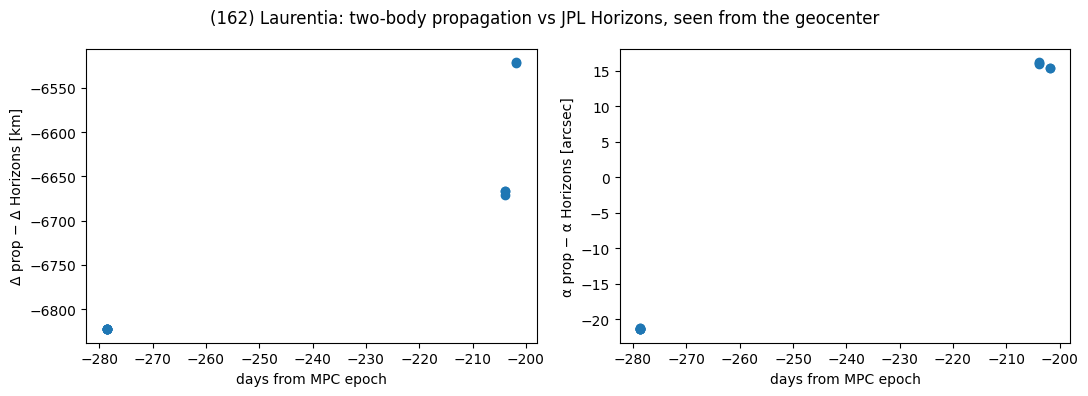

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
days = (obs_et_2 - epoch_et) / 86400
axes[0].plot(days, geometry_comparison['delta diff [km]'], 'o')
axes[0].set_xlabel('days from MPC epoch')
axes[0].set_ylabel('Δ prop − Δ Horizons [km]')
axes[1].plot(days, geometry_comparison['alpha diff [arcsec]'], 'o')
axes[1].set_xlabel('days from MPC epoch')
axes[1].set_ylabel('α prop − α Horizons [arcsec]')
fig.suptitle('(162) Laurentia: two-body propagation vs JPL Horizons, seen from the geocenter')
fig.tight_layout()
plt.show()

**Reading the results**

- Earth: SPICE (DE440) and Horizons agree to better than 1 m, so the observer position is not a source of error.
- Distance from Earth: the two-body $\Delta$ is ~6,500–6,800 km shorter than Horizons, i.e. ~0.002% of $\Delta$. This is much less than the ~18,000–34,000 km 3D position error found above: most of that error is across the line of sight, not along it.
- Phase angle: differences of ~15–21 arcsec (~0.006°), negligible for photometry (phase curves are sensitive at the ~0.1° level).

## Distance from Earth and phase angle for every observation

We add the distance from Earth (geocenter) and the phase angle to the orbital elements of every observation, and save the result to `data/obs_elements_geometry_at_obstime.parquet`.

- The elements and the asteroid state at each observation time are read from `data/obs_elements_state_at_obstime.parquet`, one row group (500k rows) at a time.
- Light-time correction: instead of propagating again with `prop2b`, the asteroid position when the light left it is approximated as `r(t - lt) = r(t) - v(t) * lt` (iterated). Over ~20 min of light time the error of this linear step is below 1 km.
- The Earth position only depends on the time, so it is computed once per distinct observation time (~47k) with SPICE.

In [23]:
def earth_geometry(state, obs_et, n_iter=3):
    """Geocentric distance and phase angle of many asteroids at once, with light-time correction.

    state : (n, 6) heliocentric ecliptic J2000 state at the observation time [km, km/s]
    obs_et : (n,) observation times [TDB seconds past J2000]
    Returns delta [AU] and phase angle [deg].
    """
    # Earth position once per distinct time
    et_unique, inverse = np.unique(obs_et, return_inverse=True)
    earth_unique = np.array([spiceypy.spkpos('EARTH', et, 'ECLIPJ2000', 'NONE', 'SUN')[0] for et in et_unique])
    r_earth = earth_unique[inverse]

    r_ast, v_ast = state[:, :3], state[:, 3:]
    lt = np.zeros(len(state))
    for _ in range(n_iter):
        r_emit = r_ast - v_ast * lt[:, None]        # asteroid when the light left it
        rho = r_emit - r_earth                      # Earth -> asteroid
        dist = np.linalg.norm(rho, axis=1)
        lt = dist / C_KM_S

    # Phase angle: angle at the asteroid between the directions to the Sun (-r_emit) and to Earth (-rho)
    cos_alpha = np.einsum('ij,ij->i', r_emit, rho) / (np.linalg.norm(r_emit, axis=1) * dist)
    alpha = np.degrees(np.arccos(np.clip(cos_alpha, -1, 1)))
    return dist / AU_KM, alpha


# Check against the exact light-time calculation done above for Laurentia
laurentia_state = np.array([propagate_orbit(mu_sun, state0, et - epoch_et) for et in obs_et_2])
delta_lin, alpha_lin = earth_geometry(laurentia_state, obs_et_2)
print('max |delta difference| [km]:', np.abs(delta_lin * AU_KM - delta_prop).max())
print('max |alpha difference| [arcsec]:', np.abs(alpha_lin - alpha_prop).max() * 3600)

max |delta difference| [km]: 0.5473074913024902
max |alpha difference| [arcsec]: 6.999299060339581e-05


In [24]:
elements_states_path = 'data/obs_elements_state_at_obstime.parquet'
out_geometry = 'data/obs_elements_geometry_at_obstime.parquet'

id_cols = ['obstime', 'mpc_row', 'mpc_designation', 'obs_et', 'dt_from_epoch_days']
element_cols = ['a', 'e', 'q', 'incl', 'node', 'peri', 'M']
elements_states_file = pq.ParquetFile(elements_states_path)

writer = None
start = time.time()
for i in range(elements_states_file.metadata.num_row_groups):
    elements = elements_states_file.read_row_group(i, columns=id_cols + element_cols)
    states = elements_states_file.read_row_group(i, columns=['obs_et'] + state_cols)

    state = np.column_stack([states[c].to_numpy() for c in state_cols])
    delta, alpha = earth_geometry(state, states['obs_et'].to_numpy())
    table = elements.append_column('delta', pa.array(delta)).append_column('phase_angle', pa.array(alpha))

    if writer is None:
        writer = pq.ParquetWriter(out_geometry, table.schema)
    writer.write_table(table)
    print(f'row group {i + 1}/{elements_states_file.metadata.num_row_groups}  ({time.time() - start:.0f} s)')
writer.close()

row group 1/16  (1 s)
row group 2/16  (2 s)
row group 3/16  (3 s)
row group 4/16  (3 s)
row group 5/16  (4 s)
row group 6/16  (5 s)
row group 7/16  (6 s)
row group 8/16  (7 s)
row group 9/16  (8 s)
row group 10/16  (9 s)
row group 11/16  (10 s)
row group 12/16  (10 s)
row group 13/16  (11 s)
row group 14/16  (12 s)
row group 15/16  (13 s)
row group 16/16  (14 s)


In [25]:
elements_states_path = 'data/obs_elements_state_at_obstime.parquet'
out_geometry = 'data/obs_elements_geometry_at_obstime.parquet'

geometry_file = pq.ParquetFile(out_geometry)
print(f"{geometry_file.metadata.num_rows:,} rows in {out_geometry}")
print(geometry_file.schema_arrow.names)

# delta [AU] and phase_angle [deg] for Laurentia, next to the Horizons values from above
laurentia = pd.read_parquet(out_geometry).sort_values('obstime')

7,954,397 rows in data/obs_elements_geometry_at_obstime.parquet
['obstime', 'mpc_row', 'mpc_designation', 'obs_et', 'dt_from_epoch_days', 'a', 'e', 'q', 'incl', 'node', 'peri', 'M', 'delta', 'phase_angle']


In [26]:
laurentia.head(20)

,obstime,mpc_row,mpc_designation,obs_et,dt_from_epoch_days,a,e,q,incl,node,peri,M,delta,phase_angle
89221,2024-11-24 02:52:28.632,1476028,2024 WR108,7.856888e+08,-561.879423,2.868990,0.225765,2.221273,6.16482,186.08849,247.05005,344.615999,1.325471,10.615497
75737,2024-11-24 02:52:28.634,1475904,2024 WM103,7.856888e+08,-561.879423,3.040543,0.026688,2.959398,11.86874,70.64331,263.61193,68.142191,2.087944,7.935540
77504,2024-11-24 02:52:28.634,1475974,2024 WM106,7.856888e+08,-561.879423,2.629166,0.173550,2.172873,6.40697,91.64543,290.27201,18.514923,1.272662,10.927084
76862,2024-11-24 02:52:28.634,1475945,2024 WE105,7.856888e+08,-561.879423,2.407631,0.158591,2.025803,4.70614,108.46160,13.82092,302.975687,1.312309,10.526987
75978,2024-11-24 02:52:28.634,1475911,2024 WT103,7.856888e+08,-561.879423,2.748888,0.030965,2.663770,6.20440,172.24532,131.22226,99.524685,1.839880,8.731895
76317,2024-11-24 02:52:28.634,1475924,2024 WG104,7.856888e+08,-561.879423,3.177119,0.174319,2.623287,27.63455,55.90244,50.14042,315.584773,1.910503,8.291352
77394,2024-11-24 02:52:28.634,1475969,2024 WF106,7.856888e+08,-561.879423,2.968481,0.100721,2.669492,5.68016,106.79055,239.99416,49.866496,1.868850,8.572940
77620,2024-11-24 02:52:28.634,1475981,2024 WT106,7.856888e+08,-561.879423,2.681809,0.055584,2.532744,6.18441,181.00631,191.45811,31.331637,1.626820,9.315697
76526,2024-11-24 02:52:28.634,1475930,2024 WP104,7.856888e+08,-561.879423,2.342354,0.158130,1.971957,8.44906,78.21746,358.97098,339.935381,1.063395,11.894153
76212,2024-11-24 02:52:28.634,1475920,2024 WC104,7.856888e+08,-561.879423,2.315902,0.231446,1.779896,4.04752,110.26567,279.87332,12.810049,0.856822,13.147745


## Absolute magnitude H of (162) Laurentia

With the HG system (Bowell et al. 1989), the apparent V magnitude is

$$V = H + 5\log_{10}(r\,\Delta) - 2.5\log_{10}\left[(1-G)\,\Phi_1(\alpha) + G\,\Phi_2(\alpha)\right]$$

$$\Phi_1(\alpha) = \exp\left[-3.33\,(\tan\tfrac{\alpha}{2})^{0.63}\right] \qquad \Phi_2(\alpha) = \exp\left[-1.87\,(\tan\tfrac{\alpha}{2})^{1.22}\right]$$

with $r$ and $\Delta$ in AU. Solving for $H$ for each observation, with $G = 0.15$ and the $r$, $\Delta$, $\alpha$ computed above (two-body propagation, light-time corrected, geocentric):

$$H = V - 5\log_{10}(r\,\Delta) + 2.5\log_{10}\left[(1-G)\,\Phi_1(\alpha) + G\,\Phi_2(\alpha)\right]$$

**Magnitudes.** We use the `mag` column of `data_mpc` (Rubin) as the apparent magnitude: $V = $ `mag`.

In [27]:
obj_test_2

,obstime,permid,provid,mag,rmsmag,mpc_row,match_by,mpc_designation,mpc_a,mpc_e,...,mpc_H,mpc_tp_jd,x,y,z,vx,vy,vz,epoch_et,obs_et
7937998,2025-09-03 08:46:25.045,162,A876 HB,13.541,0.0100,161,permid,(162) Laurentia,3.013649,0.183172,...,9.08,2461741.87859,4.172484e+08,2.400998e+08,-4.926282e+06,-10.188375,12.258956,1.696637,834235200.0,8.101613e+08
7937999,2025-09-03 08:47:04.756,162,A876 HB,13.545,0.0100,161,permid,(162) Laurentia,3.013649,0.183172,...,9.08,2461741.87859,4.172484e+08,2.400998e+08,-4.926282e+06,-10.188375,12.258956,1.696637,834235200.0,8.101613e+08
7937995,2025-09-03 08:49:04.411,162,A876 HB,13.589,0.0101,161,permid,(162) Laurentia,3.013649,0.183172,...,9.08,2461741.87859,4.172484e+08,2.400998e+08,-4.926282e+06,-10.188375,12.258956,1.696637,834235200.0,8.101614e+08
7937993,2025-09-03 08:49:44.106,162,A876 HB,13.541,0.0100,161,permid,(162) Laurentia,3.013649,0.183172,...,9.08,2461741.87859,4.172484e+08,2.400998e+08,-4.926282e+06,-10.188375,12.258956,1.696637,834235200.0,8.101615e+08
7937997,2025-09-03 08:51:43.757,162,A876 HB,13.557,0.0100,161,permid,(162) Laurentia,3.013649,0.183172,...,9.08,2461741.87859,4.172484e+08,2.400998e+08,-4.926282e+06,-10.188375,12.258956,1.696637,834235200.0,8.101616e+08
7937996,2025-09-03 08:55:02.808,162,A876 HB,13.551,0.0100,161,permid,(162) Laurentia,3.013649,0.183172,...,9.08,2461741.87859,4.172484e+08,2.400998e+08,-4.926282e+06,-10.188375,12.258956,1.696637,834235200.0,8.101618e+08
7937994,2025-09-03 08:57:42.368,162,A876 HB,13.555,0.0100,161,permid,(162) Laurentia,3.013649,0.183172,...,9.08,2461741.87859,4.172484e+08,2.400998e+08,-4.926282e+06,-10.188375,12.258956,1.696637,834235200.0,8.101619e+08
7938000,2025-11-17 02:10:12.787,162,A876 HB,15.181,0.0100,161,permid,(162) Laurentia,3.013649,0.183172,...,9.08,2461741.87859,4.172484e+08,2.400998e+08,-4.926282e+06,-10.188375,12.258956,1.696637,834235200.0,8.166175e+08
7938001,2025-11-17 03:46:59.261,162,A876 HB,14.578,0.0100,161,permid,(162) Laurentia,3.013649,0.183172,...,9.08,2461741.87859,4.172484e+08,2.400998e+08,-4.926282e+06,-10.188375,12.258956,1.696637,834235200.0,8.166233e+08
7938002,2025-11-17 03:50:33.350,162,A876 HB,14.561,0.0100,161,permid,(162) Laurentia,3.013649,0.183172,...,9.08,2461741.87859,4.172484e+08,2.400998e+08,-4.926282e+06,-10.188375,12.258956,1.696637,834235200.0,8.166235e+08


In [28]:
# Rubin magnitudes of Laurentia: the 'mag' column of data_mpc (obj_test_2 is a slice of it, sorted by obstime,
# the same order as r_prop, delta_prop and alpha_prop). We take V = mag
laurentia_phot = obj_test_2[['obstime', 'mag']].reset_index(drop=True)
laurentia_phot['V'] = laurentia_phot['mag'].astype(float)

In [29]:
def absolute_magnitude(V, r_au, delta_au, alpha_deg, G=0.15):
    """H from the apparent V magnitude with the HG phase function (Bowell et al. 1989)."""
    tan_half = np.tan(np.radians(alpha_deg) / 2)
    phi1 = np.exp(-3.33 * tan_half**0.63)
    phi2 = np.exp(-1.87 * tan_half**1.22)
    return V - 5 * np.log10(r_au * delta_au) + 2.5 * np.log10((1 - G) * phi1 + G * phi2)


laurentia_phot['r [AU]'] = r_prop / AU_KM
laurentia_phot['delta [AU]'] = delta_prop / AU_KM
laurentia_phot['alpha [deg]'] = alpha_prop
laurentia_phot['H'] = absolute_magnitude(laurentia_phot['V'], laurentia_phot['r [AU]'],
                                         laurentia_phot['delta [AU]'], laurentia_phot['alpha [deg]'])
# Horizons predicted V at the same times (from the geocentric ephemeris queried above)
laurentia_phot['V Horizons'] = hor_eph['V'].to_numpy()
laurentia_phot['V - V Horizons'] = laurentia_phot['V'] - laurentia_phot['V Horizons']
laurentia_phot

,obstime,mag,V,r [AU],delta [AU],alpha [deg],H,V Horizons,V - V Horizons
0,2025-09-03 08:46:25.045,13.541,13.541,3.526750,2.537838,3.805908,8.426955,14.204,-0.663
1,2025-09-03 08:47:04.756,13.545,13.545,3.526750,2.537837,3.805775,8.430964,14.204,-0.659
2,2025-09-03 08:49:04.411,13.589,13.589,3.526749,2.537832,3.805376,8.474992,14.204,-0.615
3,2025-09-03 08:49:44.106,13.541,13.541,3.526749,2.537831,3.805244,8.427001,14.204,-0.663
4,2025-09-03 08:51:43.757,13.557,13.557,3.526748,2.537826,3.804844,8.443029,14.204,-0.647
5,2025-09-03 08:55:02.808,13.551,13.551,3.526747,2.537818,3.804180,8.437075,14.204,-0.653
6,2025-09-03 08:57:42.368,13.555,13.555,3.526746,2.537812,3.803648,8.441111,14.204,-0.649
7,2025-11-17 02:10:12.787,15.181,15.181,3.472590,3.018385,15.592032,9.224808,15.046,0.135
8,2025-11-17 03:46:59.261,14.578,14.578,3.472531,3.019282,15.598361,8.620983,15.047,-0.469
9,2025-11-17 03:50:33.350,14.561,14.561,3.472529,3.019315,15.598593,8.603952,15.047,-0.486


In [30]:
H_jpl = hor_el['H'].iloc[0]                       # H used by JPL (Horizons)
H_mpc = obj_test_2['mpc_H'].iloc[0]                # H in MPCORB

H_rubin = laurentia_phot['H'].mean()
H_err = laurentia_phot['H'].std() / np.sqrt(len(laurentia_phot))
print(f"H from Rubin:        {H_rubin:.2f} +/- {H_err:.2f}  (std of single observations {laurentia_phot['H'].std():.2f})")
print(f"H from JPL Horizons: {H_jpl:.2f}   difference Rubin - JPL = {H_rubin - H_jpl:+.2f} mag")
print(f"H from MPCORB:       {H_mpc:.2f}   difference Rubin - MPC = {H_rubin - H_mpc:+.2f} mag")

# H per night
laurentia_phot.groupby(laurentia_phot['obstime'].dt.date)['H'].agg(['mean', 'std', 'count']).assign(
    **{'mean - H_JPL': lambda d: d['mean'] - H_jpl})

H from Rubin:        8.64 +/- 0.09  (std of single observations 0.30)
H from JPL Horizons: 9.09   difference Rubin - JPL = -0.45 mag
H from MPCORB:       9.08   difference Rubin - MPC = -0.44 mag


,mean,std,count,mean - H_JPL
obstime,,,,
2025-09-03,8.440161,0.016653,7,-0.649839
2025-11-17,8.816581,0.353638,3,-0.273419
2025-11-19,9.058189,0.040326,2,-0.031811


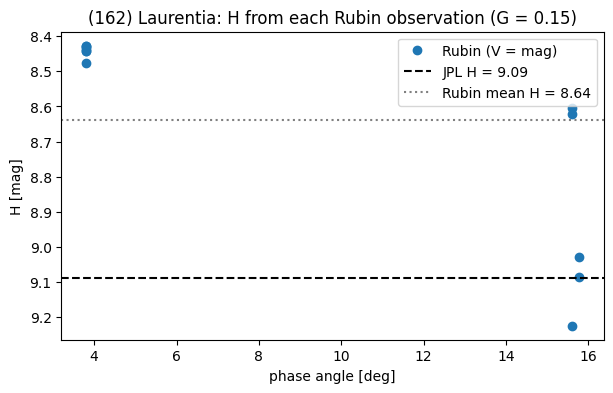

In [31]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(laurentia_phot['alpha [deg]'], laurentia_phot['H'], 'o', label='Rubin (V = mag)')
ax.axhline(H_jpl, color='k', ls='--', label=f'JPL H = {H_jpl:.2f}')
ax.axhline(H_rubin, color='gray', ls=':', label=f'Rubin mean H = {H_rubin:.2f}')
ax.set_xlabel('phase angle [deg]')
ax.set_ylabel('H [mag]')
ax.invert_yaxis()
ax.set_title('(162) Laurentia: H from each Rubin observation (G = 0.15)')
ax.legend()
plt.show()

**Reading the results**

- With $V$ = `mag`, Rubin gives $H = 8.64 \pm 0.09$, 0.45 mag brighter than JPL ($H = 9.09$) and MPCORB ($H = 9.08$).
- The single observations scatter by 0.30 mag, and the offset from JPL changes from night to night: −0.65 mag on 2025-09-03, −0.27 on 2025-11-17 and −0.03 on 2025-11-19. The column `V - V Horizons` shows the same pattern in the apparent magnitude.
- The geometry is not the cause: $r$, $\Delta$ and $\alpha$ agree with Horizons to ~0.002% and ~20 arcsec, which changes $H$ by less than 0.001 mag.
- The differences come from the photometry and the model:
  - **Band**: Rubin `mag` is measured in an LSST band (z on 2025-09-03, g and i in November), not in V. Asteroids are brighter in i and z than in V, which fits the large offset of the 2025-09-03 (z) night and of the two i observations on 2025-11-17.
  - **Rotation**: a single night samples one part of the lightcurve; amplitudes of 0.1–0.3 mag are typical.
  - **Phase function**: $G = 0.15$ is a default. The 2025-09-03 observations are at $\alpha \approx 3.8°$, where the opposition effect is strong and a wrong $G$ matters most.

## Final file: orbital elements, distance from Earth, phase angle and H for every observation

For every observation we compute $H$ with the HG formula above ($G = 0.15$, $V$ = `mag`) and save everything to `data/obs_final_elements_geometry_H.parquet`:

- identification: `obstime`, `mpc_row`, `mpc_designation`, `permid` (number), `provid` (provisional designation), `obs_et`, `dt_from_epoch_days`
- osculating elements at the observation time: `a, e, q, incl, node, peri, M` [AU, deg]
- `r` (distance from the Sun) and `delta` (distance from Earth) [AU], `phase_angle` [deg], light-time corrected, geocentric
- `mag` (Rubin) and `H`

`r` is computed here from the state vectors, at the same light-time corrected position used for `delta` and `phase_angle`: $r = |\vec r(t) - \vec v(t)\,\Delta/c|$.

The geometry and elements/state-vector files have the same rows in the same order as `data/obs_state_vector.parquet` (checked below), so `mag`, `permid` and `provid` are taken row by row from that file. Rows without `mag` get `H` = NaN.

In [32]:
geometry_path = 'data/obs_elements_geometry_at_obstime.parquet'
states_path = 'data/obs_elements_state_at_obstime.parquet'
final_path = 'data/obs_final_elements_geometry_H.parquet'

# Rubin magnitudes, in the same row order as the files built above
obs_source = pq.read_table('data/obs_elements_state.parquet', columns=['obstime', 'mpc_row', 'permid', 'provid', 'mag', 'rmsmag'])
mag_all = obs_source['mag'].to_numpy(zero_copy_only=False).astype(float)

geometry_file = pq.ParquetFile(geometry_path)
states_file = pq.ParquetFile(states_path)
assert geometry_file.metadata.num_rows == states_file.metadata.num_rows == len(mag_all)

writer = None
offset = 0
start = time.time()
for i in range(geometry_file.metadata.num_row_groups):
    geometry = geometry_file.read_row_group(i)
    states = states_file.read_row_group(i, columns=['obs_et'] + state_cols)
    n = geometry.num_rows
    rows = slice(offset, offset + n)
    # Same rows in all files
    assert np.array_equal(geometry['obs_et'].to_numpy(), states['obs_et'].to_numpy())
    assert np.array_equal(geometry['obstime'].to_numpy(), obs_source['obstime'][rows].to_numpy())
    assert np.array_equal(geometry['mpc_row'].to_numpy(), obs_source['mpc_row'][rows].to_numpy())

    # Distance from the Sun at the light-time corrected position [AU]
    pos = np.column_stack([states[c].to_numpy() for c in ['x', 'y', 'z']])
    vel = np.column_stack([states[c].to_numpy() for c in ['vx', 'vy', 'vz']])
    delta = geometry['delta'].to_numpy()
    lt = delta * AU_KM / C_KM_S
    r_sun = np.linalg.norm(pos - vel * lt[:, None], axis=1) / AU_KM

    mag = mag_all[rows]
    H = absolute_magnitude(mag, r_sun, delta, geometry['phase_angle'].to_numpy())

    table = (geometry.append_column('r', pa.array(r_sun))
                     .append_column('mag', pa.array(mag))
                     .append_column('permid', obs_source['permid'][rows])
                     .append_column('provid', obs_source['provid'][rows])
                     .append_column('H', pa.array(H)))
    # Column order: identification, elements, geometry, photometry
    table = table.select(['obstime', 'mpc_row', 'mpc_designation', 'permid', 'provid', 'obs_et', 'dt_from_epoch_days',
                          'a', 'e', 'q', 'incl', 'node', 'peri', 'M',
                          'r', 'delta', 'phase_angle', 'mag', 'H'])
    if writer is None:
        writer = pq.ParquetWriter(final_path, table.schema)
    writer.write_table(table)
    offset += n
    print(f'row group {i + 1}/{geometry_file.metadata.num_row_groups}  ({time.time() - start:.0f} s)')
writer.close()
del obs_source, mag_all

row group 1/16  (1 s)
row group 2/16  (2 s)
row group 3/16  (2 s)
row group 4/16  (3 s)
row group 5/16  (4 s)
row group 6/16  (4 s)
row group 7/16  (5 s)
row group 8/16  (6 s)
row group 9/16  (7 s)
row group 10/16  (8 s)
row group 11/16  (9 s)
row group 12/16  (9 s)
row group 13/16  (10 s)
row group 14/16  (11 s)
row group 15/16  (12 s)
row group 16/16  (12 s)


In [33]:
geometry_path = 'data/obs_elements_geometry_at_obstime.parquet'
states_path = 'data/obs_elements_state_at_obstime.parquet'
final_path = 'data/obs_final_elements_geometry_H.parquet'
final_file = pq.ParquetFile(final_path)
H_all = final_file.read(columns=['H'])['H'].to_numpy()
print(f"{final_file.metadata.num_rows:,} rows in {final_path}")
print(final_file.schema_arrow.names)
print(f"H computed for {np.isfinite(H_all).sum():,} observations ({np.isnan(H_all).sum()} without mag)")

# Check: Laurentia gives the same H as the calculation above
laurentia_final = pd.read_parquet(final_path, filters=[('mpc_designation', '==', '(162) Laurentia')]).sort_values('obstime')
print(f"Laurentia mean H: {laurentia_final['H'].mean():.2f} (above: {laurentia_phot['H'].mean():.2f}, JPL: {H_jpl:.2f})")
laurentia_final

7,954,397 rows in data/obs_final_elements_geometry_H.parquet
['obstime', 'mpc_row', 'mpc_designation', 'permid', 'provid', 'obs_et', 'dt_from_epoch_days', 'a', 'e', 'q', 'incl', 'node', 'peri', 'M', 'r', 'delta', 'phase_angle', 'mag', 'H']
H computed for 7,954,395 observations (2 without mag)
Laurentia mean H: 8.64 (above: 8.64, JPL: 9.09)


,obstime,mpc_row,mpc_designation,permid,provid,obs_et,dt_from_epoch_days,a,e,q,incl,node,peri,M,r,delta,phase_angle,mag,H
5,2025-09-03 08:46:25.045,161,(162) Laurentia,162,A876 HB,8.101613e+08,-278.633632,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.515336,3.526750,2.537838,3.805908,13.541,8.426955
6,2025-09-03 08:47:04.756,161,(162) Laurentia,162,A876 HB,8.101613e+08,-278.633172,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.515423,3.526750,2.537837,3.805775,13.545,8.430964
2,2025-09-03 08:49:04.411,161,(162) Laurentia,162,A876 HB,8.101614e+08,-278.631787,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.515684,3.526749,2.537832,3.805376,13.589,8.474992
0,2025-09-03 08:49:44.106,161,(162) Laurentia,162,A876 HB,8.101615e+08,-278.631328,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.515770,3.526749,2.537831,3.805244,13.541,8.427001
4,2025-09-03 08:51:43.757,161,(162) Laurentia,162,A876 HB,8.101616e+08,-278.629943,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.516031,3.526748,2.537826,3.804844,13.557,8.443029
3,2025-09-03 08:55:02.808,161,(162) Laurentia,162,A876 HB,8.101618e+08,-278.627639,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.516465,3.526747,2.537818,3.804180,13.551,8.437075
1,2025-09-03 08:57:42.368,161,(162) Laurentia,162,A876 HB,8.101619e+08,-278.625792,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.516813,3.526746,2.537812,3.803648,13.555,8.441111
7,2025-11-17 02:10:12.787,161,(162) Laurentia,162,A876 HB,8.166175e+08,-203.908773,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,219.592989,3.472590,3.018385,15.592032,15.181,9.224808
8,2025-11-17 03:46:59.261,161,(162) Laurentia,162,A876 HB,8.166233e+08,-203.841569,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,219.605650,3.472531,3.019282,15.598360,14.578,8.620983
9,2025-11-17 03:50:33.350,161,(162) Laurentia,162,A876 HB,8.166235e+08,-203.839091,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,219.606117,3.472529,3.019315,15.598593,14.561,8.603952


295,901 objects; Rubin H - MPCORB H: median -0.14 mag, 16-84% range [-0.28, +0.09]


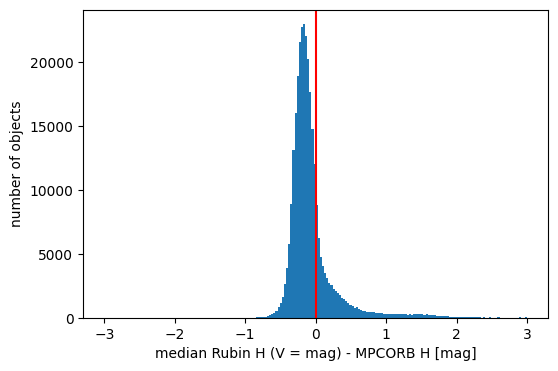

In [34]:
# One H per object: median over its observations, compared with the H in MPCORB
H_obj = (pq.read_table(final_path, columns=['mpc_row', 'H']).to_pandas()
         .groupby('mpc_row')['H'].agg(['median', 'count']))
mpc_H = pq.read_table('data/obs_elements_state.parquet', columns=['mpc_row', 'mpc_H']).to_pandas().drop_duplicates('mpc_row')
H_obj = H_obj.join(mpc_H.set_index('mpc_row')['mpc_H'].astype(float))
diff = (H_obj['median'] - H_obj['mpc_H']).dropna()
print(f"{len(H_obj):,} objects; Rubin H - MPCORB H: median {diff.median():+.2f} mag, "
      f"16-84% range [{diff.quantile(0.16):+.2f}, {diff.quantile(0.84):+.2f}]")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(diff, bins=200, range=(-3, 3))
ax.axvline(0, color='red')
ax.set_xlabel('median Rubin H (V = mag) - MPCORB H [mag]')
ax.set_ylabel('number of objects')
plt.show()

In [3]:
import pandas as pd
data_H = pd.read_parquet('data/obs_final_elements_geometry_H.parquet', engine='pyarrow')

In [5]:
data_H[data_H['provid'] == '2025 MD38']

,obstime,mpc_row,mpc_designation,permid,provid,obs_et,dt_from_epoch_days,a,e,q,incl,node,peri,M,r,delta,phase_angle,mag,H
17134,2025-04-22 02:37:21.011,1020544,2014 HR48,None,2025 MD38,7.985615e+08,-412.889928,3.15623,0.021533,3.088268,16.47987,34.3324,179.81611,338.553819,3.093176,2.177794,9.176169,21.955,17.199574
17135,2025-04-22 02:38:48.940,1020544,2014 HR48,None,2025 MD38,7.985616e+08,-412.888911,3.15623,0.021533,3.088268,16.47987,34.3324,179.81611,338.553998,3.093176,2.177800,9.176477,21.941,17.185555
17136,2025-04-22 02:39:32.840,1020544,2014 HR48,None,2025 MD38,7.985616e+08,-412.888402,3.15623,0.021533,3.088268,16.47987,34.3324,179.81611,338.554087,3.093176,2.177803,9.176631,21.928,17.172546
17137,2025-04-22 02:42:38.583,1020544,2014 HR48,None,2025 MD38,7.985618e+08,-412.886253,3.15623,0.021533,3.088268,16.47987,34.3324,179.81611,338.554465,3.093176,2.177816,9.177282,21.974,17.218506
17138,2025-04-22 02:43:22.655,1020544,2014 HR48,None,2025 MD38,7.985619e+08,-412.885743,3.15623,0.021533,3.088268,16.47987,34.3324,179.81611,338.554555,3.093176,2.177819,9.177436,21.917,17.161496
17139,2025-04-22 02:44:50.066,1020544,2014 HR48,None,2025 MD38,7.985620e+08,-412.884731,3.15623,0.021533,3.088268,16.47987,34.3324,179.81611,338.554733,3.093176,2.177825,9.177743,21.936,17.180477
17140,2025-04-22 02:46:18.177,1020544,2014 HR48,None,2025 MD38,7.985620e+08,-412.883711,3.15623,0.021533,3.088268,16.47987,34.3324,179.81611,338.554912,3.093175,2.177832,9.178051,21.942,17.186458
17141,2025-04-22 02:47:02.172,1020544,2014 HR48,None,2025 MD38,7.985621e+08,-412.883202,3.15623,0.021533,3.088268,16.47987,34.3324,179.81611,338.555001,3.093175,2.177835,9.178205,21.913,17.157449
17142,2025-04-22 02:47:46.365,1020544,2014 HR48,None,2025 MD38,7.985621e+08,-412.882690,3.15623,0.021533,3.088268,16.47987,34.3324,179.81611,338.555091,3.093175,2.177838,9.178360,21.914,17.158439
17143,2025-04-22 02:49:14.347,1020544,2014 HR48,None,2025 MD38,7.985622e+08,-412.881672,3.15623,0.021533,3.088268,16.47987,34.3324,179.81611,338.555270,3.093175,2.177844,9.178669,21.877,17.121420


In [4]:
data_H

,obstime,mpc_row,mpc_designation,permid,provid,obs_et,dt_from_epoch_days,a,e,q,incl,node,peri,M,r,delta,phase_angle,mag,H
0,2025-05-02 00:42:01.796,1487851,2025 MD8,None,2025 MD8,7.994186e+08,-402.970012,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.353219,2.901265,2.039310,12.322578,23.096,18.498641
1,2025-05-02 00:39:54.996,1487851,2025 MD8,None,2025 MD8,7.994185e+08,-402.971479,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.352912,2.901264,2.039296,12.322145,22.927,18.329673
2,2025-05-02 01:01:01.387,1487851,2025 MD8,None,2025 MD8,7.994197e+08,-402.956822,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.355973,2.901280,2.039431,12.326470,23.055,18.457356
3,2025-05-02 01:03:10.218,1487851,2025 MD8,None,2025 MD8,7.994199e+08,-402.955331,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.356284,2.901282,2.039445,12.326910,23.059,18.461323
4,2025-05-02 01:29:18.645,1487851,2025 MD8,None,2025 MD8,7.994214e+08,-402.937178,2.814204,0.119711,2.477313,4.36485,115.86923,328.92434,98.360074,2.901303,2.039611,12.332264,22.911,18.312930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7954392,2025-07-18 01:03:03.946,1311281,2020 KJ56,None,2020 KJ56,8.060727e+08,-325.955404,43.840834,0.024141,42.782463,2.73200,154.76027,143.11675,355.869914,42.785350,41.770096,0.061190,23.670,7.382559
7954393,2025-08-17 07:07:02.087,1353570,2021 LD56,None,2021 LD56,8.086865e+08,-295.702647,40.233568,0.035963,38.786632,14.75030,288.69354,17.80409,351.560323,38.803488,37.906157,0.700339,22.657,6.695863
7954394,2025-08-17 07:03:07.476,1432311,2023 PJ5,None,2023 PJ5,8.086863e+08,-295.705363,47.487819,0.328316,31.896803,3.05394,135.62001,160.71978,3.035565,31.945213,31.006109,0.688556,22.748,7.646804
7954395,2025-07-08 08:36:06.169,1432312,2023 PK5,None,2023 PK5,8.052358e+08,-335.640795,42.116883,0.120041,37.061139,8.92666,279.97838,65.56261,325.421686,38.182169,37.206504,0.434116,22.831,6.977308
